In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [2]:
df = pd.read_csv("IrisData_full.csv", header=None)
df = df.sample(frac=1).reset_index(drop=True)
df.columns = ["Sepal_length", "Sepal_width", "Petal_length", "Petal_width", "Species"]

df.head()

,Sepal_length,Sepal_width,Petal_length,Petal_width,Species
0,6.1,3.0,4.9,1.8,Iris-virginica
1,4.3,3.0,1.1,0.1,Iris-setosa
2,6.0,3.0,4.8,1.8,Iris-virginica
3,5.8,2.7,5.1,1.9,Iris-virginica
4,6.9,3.2,5.7,2.3,Iris-virginica


In [3]:
x = df.iloc[:, :4].astype(float)
y = df.iloc[:, 4]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [6]:
def euclidian_distance(a, b):
    return np.sqrt(np.sum((b - a)**2))

In [7]:
class KNN:
    def __init__(self, k):
        self.k = k

    def fit(self, x, y):
        self.x_train = np.array(x)
        self.y_train = np.array(y)

    def predict(self, new_points):
        predictions = [self.predict_class(point) for point in new_points]
        return np.array(predictions)

    def predict_class(self, new_point):
        distances = [euclidian_distance(point, new_point) for point in self.x_train]

        k_nearest_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = [self.y_train[i] for i in k_nearest_indices]

        most_common = Counter(k_nearest_labels).most_common(1)[0][0]

        return most_common

In [30]:
knn = KNN(13)
knn.fit(x_train, y_train)
predictions = knn.predict(x_test)

accuracy = np.mean(predictions == np.array(y_test)) * 100
print("Accuracy:", accuracy)

Accuracy: 93.33333333333333


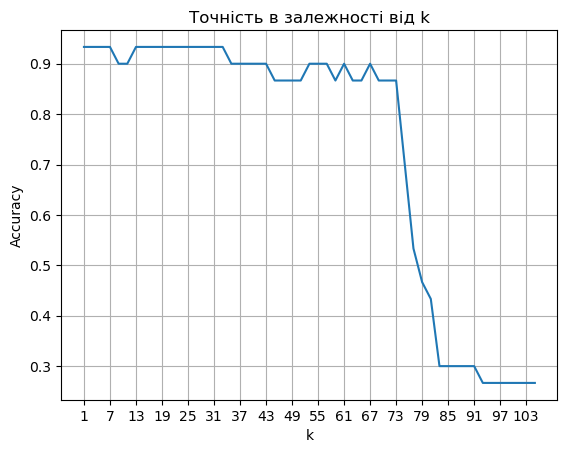

In [27]:
k_values = range(1, 107, 2)
accuracies = []

for k in k_values:
    knn = KNN(k)
    knn.fit(x_train, y_train)
    predictions = knn.predict(x_test)
    accuracy = np.mean(predictions == np.array(y_test))
    accuracies.append(accuracy)

plt.plot(k_values, accuracies)
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Точність в залежності від k")
plt.xticks(range(1, 107, 6))
plt.grid(True)
plt.show()